# 01 — Keşifsel Veri Analizi (EDA)

**Kural:** EDA yalnızca **development** verisinde (n = 3.295) yapılır. Test kümesi bu notebook'ta hiç kullanılmaz.
EDA'dan hiçbir özellik eleme / supervised seçim kararı çıkarılmaz; amaç veri kalitesini anlamak ve hipotez üretmektir.

## 0. Kurulum

In [1]:
# Google Colab'da çalıştırılıyorsa aşağıdaki satırların başındaki '#' kaldırılır:
# !git clone https://github.com/mesutissever/ysa-midterm-mlp-nested-cv.git
# %cd ysa-midterm-mlp-nested-cv
# !pip install -q -r requirements.txt
# Ham veri (data/bank-additional.csv) yoksa ilk okumada UCI'den otomatik indirilir ve sha256 ile doğrulanır.

In [2]:
import sys, os
sys.path.insert(0, os.path.abspath("."))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data import load_seeds, get_dev_test, TARGET

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid")

FIG = "figures"
RES = "results"
os.makedirs(FIG, exist_ok=True)
os.makedirs(RES, exist_ok=True)

def savefig(name):
    plt.savefig(f"{FIG}/{name}.png", dpi=150, bbox_inches="tight")

seeds = load_seeds()
df_dev, _ = get_dev_test()     # test kümesi '_' ile atılıyor, KULLANILMAYACAK
print("Development:", df_dev.shape)

Development: (3295, 20)


## 1. Genel yapı: özellik tipleri ve benzersiz değerler

In [3]:
NUM_COLS = ["age", "campaign", "pdays", "previous", "emp.var.rate",
            "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
CAT_COLS = ["job", "marital", "education", "default", "housing", "loan",
            "contact", "month", "day_of_week", "poutcome"]
assert set(NUM_COLS + CAT_COLS + [TARGET]) == set(df_dev.columns)

overview = pd.DataFrame({
    "tip": ["sayısal" if c in NUM_COLS else "kategorik" for c in NUM_COLS + CAT_COLS],
    "dtype": df_dev[NUM_COLS + CAT_COLS].dtypes.astype(str).values,
    "benzersiz": df_dev[NUM_COLS + CAT_COLS].nunique().values,
    "NaN": df_dev[NUM_COLS + CAT_COLS].isna().sum().values,
}, index=NUM_COLS + CAT_COLS)
print(f"Sayısal: {len(NUM_COLS)}, Kategorik: {len(CAT_COLS)}")
print("Birebir kopya satır (development):", int(df_dev.duplicated().sum()))
overview

Sayısal: 9, Kategorik: 10
Birebir kopya satır (development): 12


,tip,dtype,benzersiz,NaN
age,sayısal,int64,67,0
campaign,sayısal,int64,25,0
pdays,sayısal,int64,20,0
previous,sayısal,int64,7,0
emp.var.rate,sayısal,float64,10,0
cons.price.idx,sayısal,float64,26,0
cons.conf.idx,sayısal,float64,26,0
euribor3m,sayısal,float64,222,0
nr.employed,sayısal,float64,11,0
job,kategorik,str,12,0


## 2. Eksik ve özel kodlu değerler (`unknown`, `pdays = 999`)

In [4]:
special = pd.DataFrame({
    "unknown_n": [(df_dev[c] == "unknown").sum() for c in CAT_COLS],
    "unknown_%": [(df_dev[c] == "unknown").mean() * 100 for c in CAT_COLS],
}, index=CAT_COLS)
special = special[special["unknown_n"] > 0].sort_values("unknown_n", ascending=False)

pdays999 = (df_dev["pdays"] == 999)
print(f"pdays = 999 (daha önce temas yok): {pdays999.sum()} / {len(df_dev)} = %{pdays999.mean()*100:.2f}")
print(f"previous = 0: %{(df_dev['previous'] == 0).mean()*100:.2f}")
print("poutcome dağılımı:"); print(df_dev["poutcome"].value_counts())

special.to_csv(f"{RES}/eda_unknown_counts.csv")
special

pdays = 999 (daha önce temas yok): 3172 / 3295 = %96.27
previous = 0: %85.64
poutcome dağılımı:
poutcome
nonexistent    2822
failure         364
success         109
Name: count, dtype: int64


,unknown_n,unknown_%
default,627,19.029
education,144,4.370
housing,87,2.640
loan,87,2.640
job,33,1.002
marital,8,0.243


In [5]:
# 'unknown' olan ve olmayan gruplarda pozitif oran (betimsel; seçim için KULLANILMAZ)
rows = []
for c in special.index:
    m = df_dev[c] == "unknown"
    rows.append({"özellik": c, "pos_rate_unknown": df_dev.loc[m, TARGET].mean(),
                 "pos_rate_diğer": df_dev.loc[~m, TARGET].mean()})
pd.DataFrame(rows).set_index("özellik")

,pos_rate_unknown,pos_rate_diğer
özellik,,
default,0.057,0.122
education,0.160,0.107
housing,0.092,0.110
loan,0.092,0.110
job,0.091,0.110
marital,0.125,0.110


## 3. Sınıf dağılımı

            n      %
no (0)   2934 89.044
yes (1)   361 10.956
Tüm örneklere 'no' diyen model accuracy ≈ %89.0


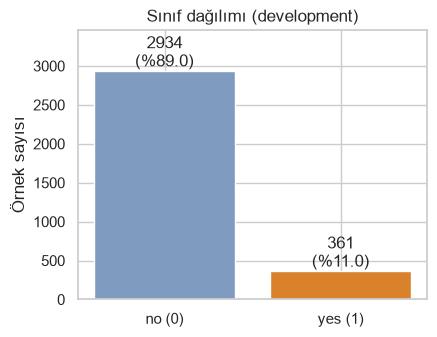

In [6]:
cls = df_dev[TARGET].value_counts().sort_index()
cls_tbl = pd.DataFrame({"n": cls, "%": cls / cls.sum() * 100})
cls_tbl.index = ["no (0)", "yes (1)"]
print(cls_tbl)
print(f"Tüm örneklere 'no' diyen model accuracy ≈ %{cls_tbl['%'].iloc[0]:.1f}")

fig, ax = plt.subplots(figsize=(4.5, 3.5))
ax.bar(cls_tbl.index, cls_tbl["n"], color=["#7f9cc0", "#d9822b"])
for i, (n, p) in enumerate(zip(cls_tbl["n"], cls_tbl["%"])):
    ax.text(i, n, f"{n}\n(%{p:.1f})", ha="center", va="bottom")
ax.set_ylabel("Örnek sayısı"); ax.set_title("Sınıf dağılımı (development)")
ax.set_ylim(0, cls_tbl["n"].max() * 1.18)
savefig("eda_class_dist"); plt.show()

**Yorum (doldur):** Pozitif sınıf ≈ %11. Accuracy dengesiz veride yanıltıcıdır; bu nedenle birincil metrik
pozitif sınıfa odaklanan **AP**'dir. Rastgele bir sınıflandırıcının AP beklentisi pozitif oranına (~0,11) eşittir bu, AP için doğal alt sınırdır.

## 4. Sayısal özellikler: tanımlayıcı istatistikler, histogram ve boxplot

In [7]:
d = df_dev[NUM_COLS]
desc = pd.DataFrame({
    "ortalama": d.mean(), "medyan": d.median(), "SD": d.std(),
    "Q1": d.quantile(.25), "Q3": d.quantile(.75),
    "IQR": d.quantile(.75) - d.quantile(.25),
    "min": d.min(), "maks": d.max(), "çarpıklık": d.skew(),
})
desc.to_csv(f"{RES}/eda_numeric_desc.csv")
desc

,ortalama,medyan,SD,Q1,Q3,IQR,min,maks,çarpıklık
age,40.033,38.000,10.363,32.000,47.000,15.000,18.000,88.000,0.743
campaign,2.540,2.000,2.575,1.000,3.000,2.000,1.000,35.000,3.985
pdays,961.933,999.000,188.268,999.000,999.000,0.000,0.000,999.000,-4.884
previous,0.185,0.000,0.527,0.000,0.000,0.000,0.000,6.000,4.072
emp.var.rate,0.094,1.100,1.559,-1.800,1.400,3.200,-3.400,1.400,-0.738
cons.price.idx,93.583,93.798,0.580,93.075,93.994,0.919,92.201,94.767,-0.219
cons.conf.idx,-40.500,-41.800,4.615,-42.700,-36.400,6.300,-50.800,-26.900,0.281
euribor3m,3.630,4.857,1.731,1.344,4.961,3.617,0.635,5.045,-0.728
nr.employed,"5,166.697","5,191.000",73.886,"5,099.100","5,228.100",129.000,"4,963.600","5,228.100",-1.090


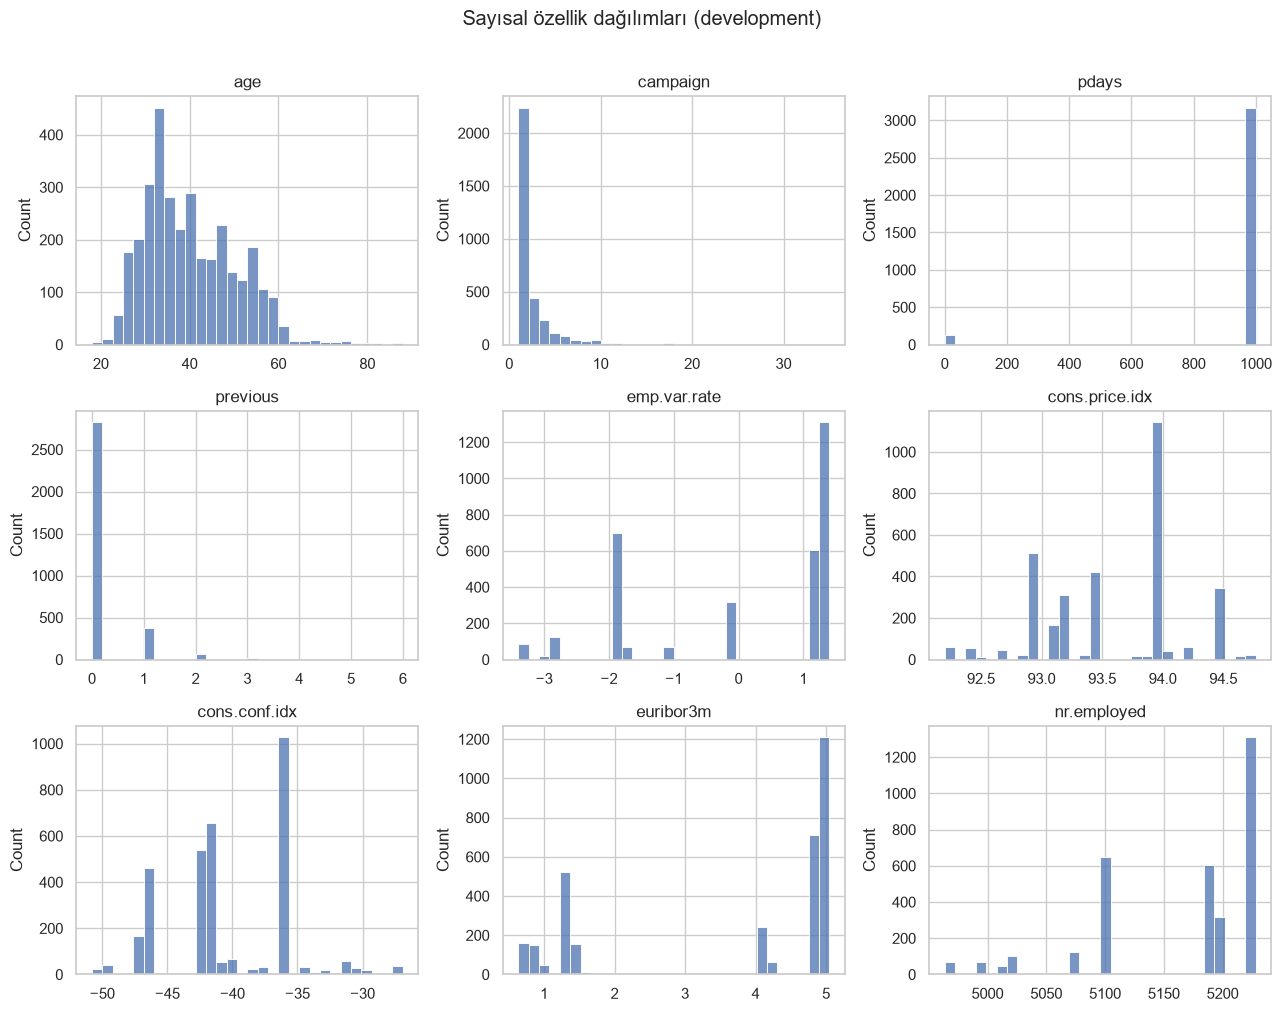

In [8]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10))
for ax, c in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df_dev[c], bins=30, ax=ax, color="#4c72b0")
    ax.set_title(c)
    ax.set_xlabel("")
fig.suptitle("Sayısal özellik dağılımları (development)", y=1.01)
plt.tight_layout(); savefig("eda_numeric_hist"); plt.show()

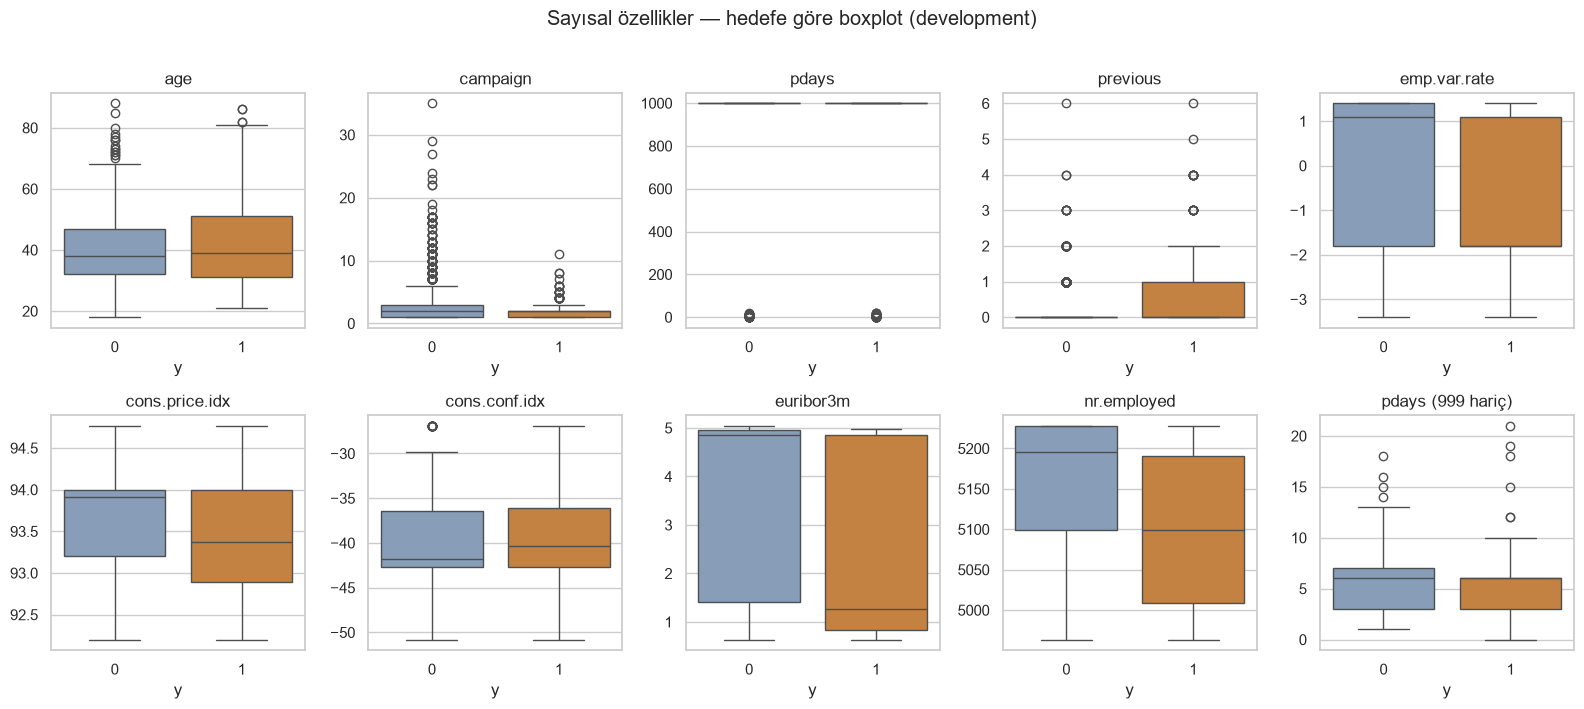

In [9]:
# Boxplot: hedefe göre (betimsel). pdays'de 999 özel kod olduğundan ayrıca 999 hariç gösteriliyor.
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
plot_cols = NUM_COLS + ["pdays (999 hariç)"]
for ax, c in zip(axes.ravel(), plot_cols):
    if c == "pdays (999 hariç)":
        sub = df_dev[df_dev["pdays"] != 999]
        sns.boxplot(x=sub[TARGET], y=sub["pdays"], ax=ax, hue=sub[TARGET], palette=["#7f9cc0", "#d9822b"], legend=False)
    else:
        sns.boxplot(x=df_dev[TARGET], y=df_dev[c], ax=ax, hue=df_dev[TARGET], palette=["#7f9cc0", "#d9822b"], legend=False)
    ax.set_title(c); ax.set_xlabel("y"); ax.set_ylabel("")
fig.suptitle("Sayısal özellikler — hedefe göre boxplot (development)", y=1.01)
plt.tight_layout(); savefig("eda_numeric_box"); plt.show()

## 5. Kategorik özellikler: frekans tabloları ve çubuk grafikler

In [10]:
for c in CAT_COLS:
    t = pd.DataFrame({"n": df_dev[c].value_counts(),
                      "%": df_dev[c].value_counts(normalize=True) * 100,
                      "pos_rate": df_dev.groupby(c)[TARGET].mean()})
    print(f"\n=== {c} ===")
    print(t.sort_values("n", ascending=False).to_string(float_format=lambda x: f"{x:.3f}"))


=== job ===
                 n      %  pos_rate
job                                
admin.         818 24.825     0.137
blue-collar    695 21.093     0.065
technician     557 16.904     0.117
services       327  9.924     0.095
management     256  7.769     0.082
retired        133  4.036     0.241
self-employed  129  3.915     0.085
entrepreneur   110  3.338     0.055
housemaid       90  2.731     0.100
unemployed      83  2.519     0.133
student         64  1.942     0.234
unknown         33  1.002     0.091

=== marital ===
             n      %  pos_rate
marital                        
married   2008 60.941     0.101
single     927 28.134     0.133
divorced   352 10.683     0.097
unknown      8  0.243     0.125

=== education ===
                        n      %  pos_rate
education                                 
university.degree    1000 30.349     0.131
high.school           742 22.519     0.100
basic.9y              464 14.082     0.073
professional.course   434 13.171     0.1

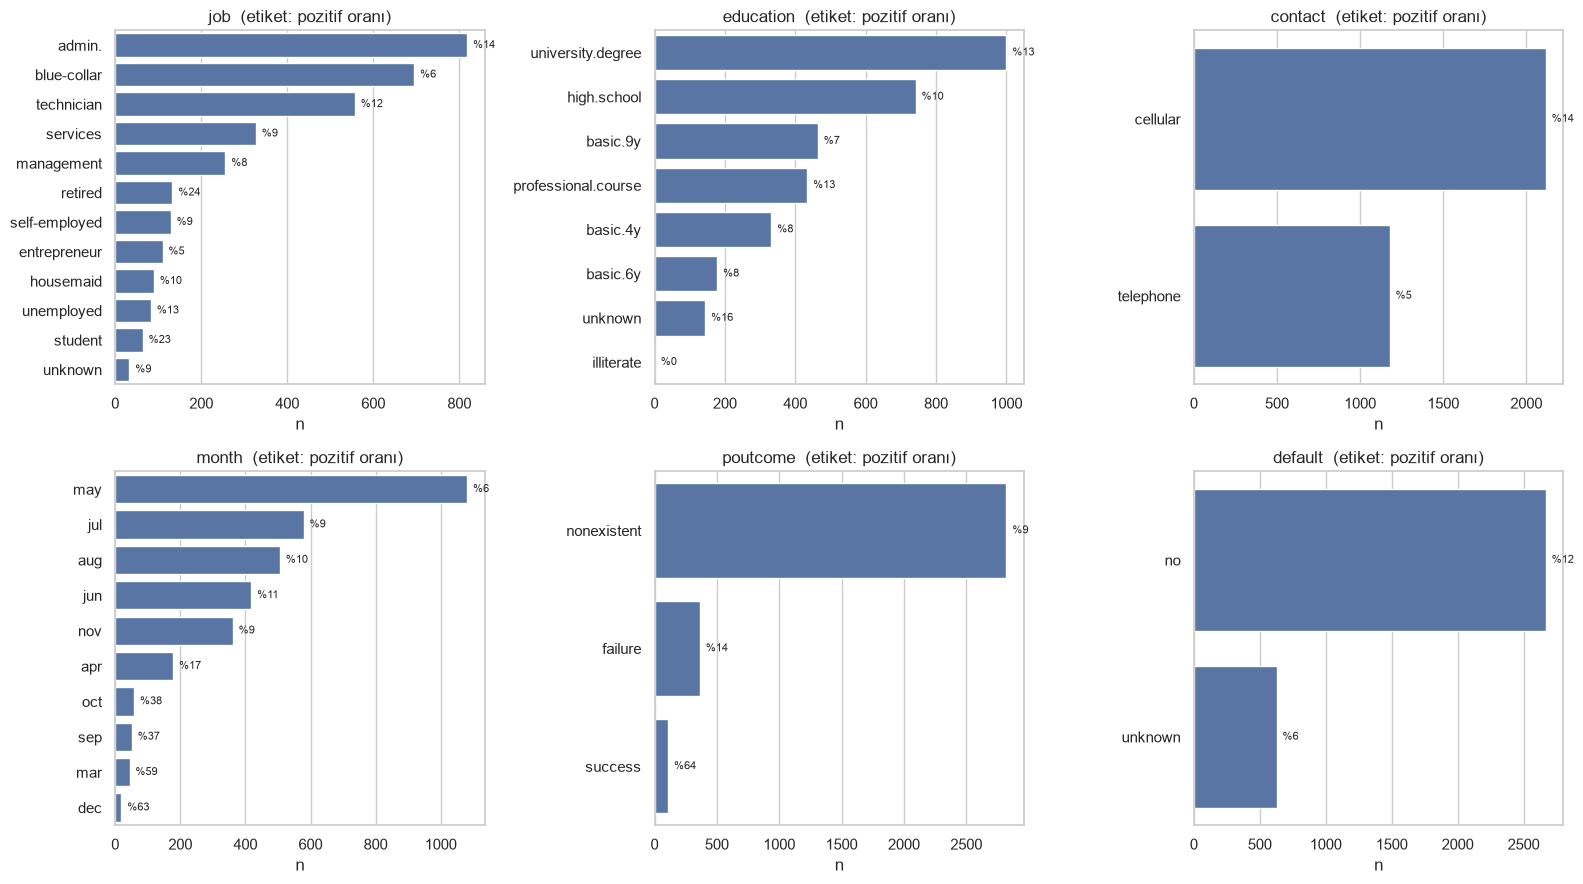

In [11]:
SEL = ["job", "education", "contact", "month", "poutcome", "default"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, c in zip(axes.ravel(), SEL):
    order = df_dev[c].value_counts().index
    sns.countplot(y=df_dev[c], order=order, ax=ax, color="#4c72b0")
    rate = df_dev.groupby(c)[TARGET].mean().reindex(order)
    for i, (n, r) in enumerate(zip(df_dev[c].value_counts().reindex(order), rate)):
        ax.text(n, i, f"  %{r*100:.0f}", va="center", fontsize=8)
    ax.set_title(f"{c}  (etiket: pozitif oranı)"); ax.set_xlabel("n"); ax.set_ylabel("")
plt.tight_layout(); savefig("eda_categorical_bars"); plt.show()

## 6. Korelasyon matrisi ve hedefe göre betimsel karşılaştırma

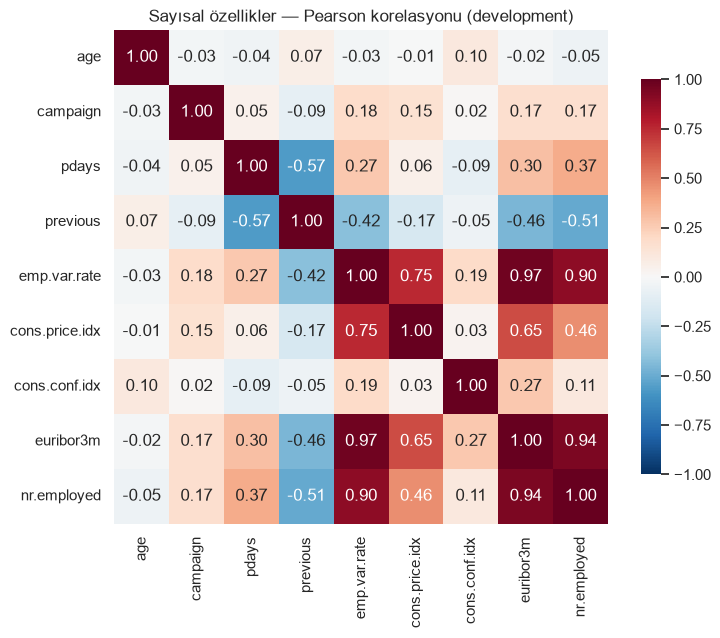

|r| >= 0.7 olan çiftler:
emp.var.rate  euribor3m        0.970
euribor3m     nr.employed      0.942
emp.var.rate  nr.employed      0.896
              cons.price.idx   0.751
dtype: float64


In [12]:
corr = df_dev[NUM_COLS].corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": .8})
ax.set_title("Sayısal özellikler — Pearson korelasyonu (development)")
plt.tight_layout(); savefig("eda_corr"); plt.show()

high = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack()
        .loc[lambda s: s.abs() >= 0.7].sort_values(key=abs, ascending=False))
print("|r| >= 0.7 olan çiftler:"); print(high.round(3))

In [13]:
by_target = df_dev.groupby(TARGET)[NUM_COLS].agg(["mean", "median"]).T.unstack()
by_target.to_csv(f"{RES}/eda_numeric_by_target.csv")
by_target

y                      0                   1          
                    mean    median      mean    median
age               39.762    38.000    42.235    39.000
campaign           2.608     2.000     1.981     2.000
pdays            983.437   999.000   787.158   999.000
previous           0.142     0.000     0.537     0.000
emp.var.rate       0.249     1.100    -1.169    -1.800
cons.price.idx    93.604    93.918    93.418    93.369
cons.conf.idx    -40.583   -41.800   -39.822   -40.300
euribor3m          3.814     4.857     2.140     1.262
nr.employed    5,175.806 5,195.800 5,092.667 5,099.100

## 7. Aykırı değerler (IQR ve yüzdelik yaklaşımı) — işaretleme, silme yok

In [14]:
rows = []
for c in NUM_COLS:
    x = df_dev[c]
    q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    p1, p99 = x.quantile([.01, .99])
    rows.append({"özellik": c, "IQR_alt": lo, "IQR_üst": hi,
                 "IQR_dışı_n": int(((x < lo) | (x > hi)).sum()),
                 "IQR_dışı_%": ((x < lo) | (x > hi)).mean() * 100,
                 "P1": p1, "P99": p99,
                 "P1-P99_dışı_n": int(((x < p1) | (x > p99)).sum())})
outl = pd.DataFrame(rows).set_index("özellik")
outl.to_csv(f"{RES}/eda_outliers.csv")
outl

,IQR_alt,IQR_üst,IQR_dışı_n,IQR_dışı_%,P1,P99,P1-P99_dışı_n
özellik,,,,,,,
age,9.500,69.500,32,0.971,24.000,68.060,62
campaign,-2.000,6.000,186,5.645,1.000,14.000,29
pdays,999.000,999.000,123,3.733,3.000,999.000,8
previous,0.000,0.000,473,14.355,0.000,2.000,28
emp.var.rate,-6.600,6.200,0,0.000,-3.400,1.400,0
cons.price.idx,91.697,95.373,0,0.000,92.201,94.601,22
cons.conf.idx,-52.150,-26.950,36,1.093,-50.000,-26.900,22
euribor3m,-4.081,10.386,0,0.000,0.668,4.968,50
nr.employed,"4,905.600","5,421.600",0,0.000,"4,963.600","5,228.100",0


**Not:** `pdays` için IQR "aykırı" olarak 999 *olmayan* değerleri işaretler (çünkü değerlerin ~%96'sı 999) — bu, özel kodun
aykırı değer mantığıyla ele alınamayacağını gösterir. `previous` için de benzer durum geçerlidir.
Öneri: silme yok; `campaign` gibi sağa çarpık değişkenler için **eğitim katında öğrenilen 1.–99. yüzdelik kırpma** bir seçenek
olarak arama uzayına (R1–R6) eklenir; etkisi iç CV ile değerlendirilir.

## 8. Deney hipotezleri (EDA bulgularına dayalı, outer CV görülmeden önce)

*(Aşağıdakileri çıktılara bakarak kendi cümlelerinle kesinleştir; sayıları yukarıdaki tablolardan al.)*

- **H1 — Ölçekleme / aykırı değer:** `campaign`, `previous` sağa çarpık ve IQR dışı değer içeriyor. Eğitim katında öğrenilmiş kırpma
  veya RobustScaler, StandardScaler'a göre daha yüksek iç CV AP verir; MinMaxScaler aykırı değere duyarlı olduğundan StandardScaler'dan
  düşük AP verir (M1 ve M4).
- **H2 — Optimizer:** Aynı LR = 0,001'de SGD+Momentum, Adam/AdamW'den daha yavaş yakınsar ve daha düşük AP'ye ulaşır (M1, M2, M3).
- **H3 — Mimari:** n ≈ 3.300 ve girdi boyutu ≈ 61 iken (64,32) mimarisi (32,)'ye göre anlamlı AP kazancı sağlamaz (M1 ve M5).
- **H4 — LR planlaması:** ReduceLROnPlateau kapalıyken (M6) erken durdurma daha erken tetiklenir ve AP bir miktar düşer.